# Experiment 14 — Historical HDB resale features + LightGBM

The resale-price file is joined by cleaned location/type keys and rental month. Every resale feature for rental month *t* uses only resale transactions with registration month strictly before *t*. The experiment compares compact, Exp 9's best feature set, and that same best set plus resale features on the same chronological validation period.

In [7]:
class RentalTargetFeatureTransformer:
    """Exp 9 target features, with prior-only values for training rows."""

    def fit(self, history):
        self.global_mean_ = history[TARGET].mean()
        self.group_mean_ = history.groupby(['TOWN', 'FLAT_TYPE'])[TARGET].mean()
        self.monthly_mean_ = history.groupby('period')[TARGET].mean()
        return self

    def transform(self, frame):
        result = frame[['TOWN', 'FLAT_TYPE', 'period']].copy()
        result['monthly_target_lag'] = (result['period'] - 24).map(self.monthly_mean_).fillna(self.global_mean_)
        group_mean = pd.Series(result.set_index(['TOWN', 'FLAT_TYPE']).index.map(self.group_mean_), index=result.index)
        result['town_flat_type_target_mean'] = group_mean.fillna(self.global_mean_)
        return result[['monthly_target_lag', 'town_flat_type_target_mean']]

    def fit_transform_train(self, history):
        self.fit(history)
        grouped = history.groupby(['TOWN', 'FLAT_TYPE', 'period'], as_index=False)[TARGET].agg(['sum', 'count']).reset_index().sort_values(['TOWN', 'FLAT_TYPE', 'period'])
        grouped['prior_sum'] = grouped.groupby(['TOWN', 'FLAT_TYPE'])['sum'].cumsum() - grouped['sum']
        grouped['prior_count'] = grouped.groupby(['TOWN', 'FLAT_TYPE'])['count'].cumsum() - grouped['count']
        grouped['town_flat_type_target_mean'] = grouped['prior_sum'] / grouped['prior_count'].replace(0, np.nan)
        global_monthly = history.groupby('period')[TARGET].agg(['sum', 'count']).sort_index()
        global_prior = (global_monthly['sum'].cumsum() - global_monthly['sum']) / (global_monthly['count'].cumsum() - global_monthly['count']).replace(0, np.nan)
        result = history[['TOWN', 'FLAT_TYPE', 'period']].merge(grouped[['TOWN', 'FLAT_TYPE', 'period', 'town_flat_type_target_mean']], on=['TOWN', 'FLAT_TYPE', 'period'], how='left')
        result['town_flat_type_target_mean'] = result['town_flat_type_target_mean'].fillna(result['period'].map(global_prior))
        result['monthly_target_lag'] = (result['period'] - 24).map(self.monthly_mean_).fillna(result['period'].map(global_prior))
        return result[['monthly_target_lag', 'town_flat_type_target_mean']]

def nearest_mrt_name(base):
    stations = datasets['mrt'][['NAME', 'LATITUDE', 'LONGITUDE']].dropna()
    _, index = cKDTree(stations[['LATITUDE', 'LONGITUDE']].to_numpy() * [111.0, 110.96]).query(base[['LATITUDE', 'LONGITUDE']].to_numpy() * [111.0, 110.96])
    return pd.Series(stations['NAME'].astype(object).to_numpy()[index], name='nearest_mrt_name')

def nearest_geojson_name(base, filename, field, name):
    with (project_root / 'data' / 'possible_additional_features' / filename).open() as handle:
        geojson = json.load(handle)
    points = pd.DataFrame([
        {'longitude': item['geometry']['coordinates'][0], 'latitude': item['geometry']['coordinates'][1], name: item['properties'][field]}
        for item in geojson['features'] if item.get('geometry', {}).get('type') == 'Point'
    ]).dropna()
    _, index = cKDTree(points[['longitude', 'latitude']].to_numpy() * [110.96, 111.0]).query(base[['LONGITUDE', 'LATITUDE']].to_numpy() * [110.96, 111.0])
    return pd.Series(points[name].astype(object).to_numpy()[index], name=name)

def make_exp9_best_features(raw_history, raw_future, history_base, future_base):
    history = history_base[['TOWN', 'FLAT_TYPE']].reset_index(drop=True).assign(period=raw_history['period'].to_numpy(), **{TARGET: raw_history[TARGET].to_numpy()})
    future = future_base[['TOWN', 'FLAT_TYPE']].reset_index(drop=True).assign(period=raw_future['period'].to_numpy())
    transformer = RentalTargetFeatureTransformer()
    history_target = transformer.fit_transform_train(history)
    future_target = transformer.transform(future)
    def combine(base, target):
        return pd.concat([
            base[compact_features].reset_index(drop=True), target.reset_index(drop=True),
            nearest_mrt_name(base).reset_index(drop=True),
            nearest_geojson_name(base, 'TouristAttractions.geojson', 'PAGETITLE', 'nearest_tourist_attraction_name').reset_index(drop=True),
            nearest_geojson_name(base, 'MonumentsGEOJSON.geojson', 'NAME', 'nearest_monument_name').reset_index(drop=True),
        ], axis=1)[BEST_FEATURES]
    return combine(history_base, history_target), combine(future_base, future_target)


In [8]:
from pathlib import Path
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lightgbm import LGBMRegressor
from scipy.spatial import cKDTree
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

configured_root = os.environ.get('KDDM_PROJECT_ROOT')
roots = ([Path(configured_root)] if configured_root else []) + [Path.cwd(), *Path.cwd().parents]
project_root = next((root for root in roots if (root / 'exploration/metul/preprocessing.py').exists()), None)
if project_root is None:
    raise FileNotFoundError('Set KDDM_PROJECT_ROOT to the project directory.')
sys.path.insert(0, str(project_root / 'exploration' / 'metul'))
from preprocessing import RentalPreprocessor, categorical_clean, load_datasets

TARGET = 'MONTHLY_RENT'
RESALE_PATH = project_root / 'data' / 'possible_additional_features' / 'ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv'
compact_features = ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'FLOOR_AREA_SQM', 'approval_date_num', 'approval_month', 'coe_quota_premium_mean', 'YEAR_COMPLETED', 'MAX_FLOOR', 'mrt_dist_nearest_km', 'mall_dist_nearest_km']
resale_features = ['block_median_resale_psm', 'street_median_resale_psm', 'town_flat_type_resale_psm', 'resale_price_growth_12m']
best_target_features = ['monthly_target_lag', 'town_flat_type_target_mean', 'nearest_mrt_name', 'nearest_tourist_attraction_name', 'nearest_monument_name']
BEST_FEATURES = compact_features + best_target_features


In [9]:
class HistoricalResaleFeatures:
    """Create resale features as-of, never including the current/future rental month."""

    def __init__(self, resale):
        data = resale.rename(columns={'town': 'TOWN', 'flat_type': 'FLAT_TYPE', 'block': 'BLOCK', 'street_name': 'STREET'}).copy()
        data = categorical_clean(data, columns=['TOWN', 'FLAT_TYPE', 'BLOCK', 'STREET'], context='resale keys', log=False)
        data['period'] = pd.to_datetime(data['month'] + '-01').dt.to_period('M')
        data['resale_psm'] = data['resale_price'] / data['floor_area_sqm']
        self.data = data.dropna(subset=['resale_psm']).copy()
        self._median_cache = {}
        self._monthly_cache = {}

    @staticmethod
    def _key(value):
        return value if isinstance(value, tuple) else (value,)

    def _median_series(self, keys):
        key = tuple(keys)
        if key not in self._median_cache:
            grouped = self.data.sort_values('period').groupby(list(keys), dropna=False)
            self._median_cache[key] = {
                self._key(group_key): (group['period'].astype(int).to_numpy(), group['resale_psm'].to_numpy())
                for group_key, group in grouped
            }
        return self._median_cache[key]

    def historical_median(self, rental_keys, keys):
        output = np.full(len(rental_keys), np.nan)
        lookup = self._median_series(keys)
        # Work group-by-group: typically ~50 requested months per location,
        # not one median calculation per rental row.
        for group_key, index in rental_keys.groupby(list(keys), dropna=False).groups.items():
            period_values, psm_values = lookup.get(self._key(group_key), (None, None))
            if period_values is None:
                continue
            requested = rental_keys.loc[index, 'period'].astype(int)
            for period in requested.unique():
                cutoff = np.searchsorted(period_values, period, side='left')
                if cutoff:
                    output[np.asarray(index)[requested.to_numpy() == period]] = np.median(psm_values[:cutoff])
        return pd.Series(output, index=rental_keys.index)

    def _monthly_psm(self):
        if 'town_flat_type' not in self._monthly_cache:
            self._monthly_cache['town_flat_type'] = self.data.groupby(['TOWN', 'FLAT_TYPE', 'period'], as_index=False)['resale_psm'].median()
        return self._monthly_cache['town_flat_type']

    def growth_12m(self, rental_keys):
        monthly = self._monthly_psm()
        lookup = {(town, flat_type, period.ordinal): psm for town, flat_type, period, psm in monthly.itertuples(index=False, name=None)}
        result = np.full(len(rental_keys), np.nan)
        for position, row in enumerate(rental_keys[['TOWN', 'FLAT_TYPE', 'period']].itertuples(index=False, name=None)):
            town, flat_type, period = row
            # Latest usable observed month is t-1; compare it with t-13.
            recent = lookup.get((town, flat_type, (period - 1).ordinal))
            previous = lookup.get((town, flat_type, (period - 13).ordinal))
            if recent is not None and previous not in (None, 0):
                result[position] = recent / previous - 1
        return pd.Series(result, index=rental_keys.index)

    def transform(self, rental_base, rental_period):
        keys = rental_base[['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE']].reset_index(drop=True).copy()
        keys['period'] = pd.Series(rental_period).reset_index(drop=True)
        # Successive historical fallbacks retain a value for new/unseen blocks.
        global_keys = keys.assign(_global='all')
        self.data['_global'] = 'all'
        global_median = self.historical_median(global_keys, ['_global'])
        town_flat = self.historical_median(keys, ['TOWN', 'FLAT_TYPE']).fillna(global_median)
        street = self.historical_median(keys, ['TOWN', 'STREET']).fillna(town_flat)
        block = self.historical_median(keys, ['TOWN', 'BLOCK']).fillna(street)
        growth = self.growth_12m(keys).fillna(0.0)
        return pd.DataFrame({
            'block_median_resale_psm': block,
            'street_median_resale_psm': street,
            'town_flat_type_resale_psm': town_flat,
            'resale_price_growth_12m': growth,
        })


In [10]:
_, datasets = load_datasets(project_root / 'data')
raw = datasets['train'].copy()
raw['period'] = pd.to_datetime(raw['RENT_APPROVAL_DATE'] + '-01').dt.to_period('M')
periods = np.sort(raw['period'].unique())
cutoff = periods[int(len(periods) * 0.80)]
raw_fit = raw.loc[raw['period'] < cutoff].copy()
raw_valid = raw.loc[raw['period'] >= cutoff].copy()
resale = pd.read_csv(RESALE_PATH)
print(f'Resale rows={len(resale):,}; coverage={resale.month.min()} to {resale.month.max()}')
print(f'Rental cutoff={cutoff}; fit={len(raw_fit):,}; validation={len(raw_valid):,}')

# The rental preprocessor is fit only on the outer fit history.
preprocessor = RentalPreprocessor(datasets)
fit_base = preprocessor.fit_transform(raw_fit.drop(columns=['period', TARGET]))
valid_base = preprocessor.transform(raw_valid.drop(columns=['period', TARGET]))
resale_transformer = HistoricalResaleFeatures(resale)
fit_resale = resale_transformer.transform(fit_base, raw_fit['period'])
valid_resale = resale_transformer.transform(valid_base, raw_valid['period'])
fit_x_compact = fit_base[compact_features].reset_index(drop=True)
valid_x_compact = valid_base[compact_features].reset_index(drop=True)
fit_x_best, valid_x_best = make_exp9_best_features(raw_fit, raw_valid, fit_base, valid_base)
fit_x_best_resale = pd.concat([fit_x_best, fit_resale], axis=1)
valid_x_best_resale = pd.concat([valid_x_best, valid_resale], axis=1)
fit_y = raw_fit[TARGET].astype(float).reset_index(drop=True)
valid_y = raw_valid[TARGET].astype(float).reset_index(drop=True)
display(pd.DataFrame({'fit_missing_rate': fit_resale.isna().mean(), 'validation_missing_rate': valid_resale.isna().mean(), 'fit_median': fit_resale.median(), 'validation_median': valid_resale.median()}))
display(pd.concat([fit_base[['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE']].head(), fit_resale.head()], axis=1))
print(f'Feature counts — compact: {fit_x_compact.shape[1]}; Exp 9 best: {fit_x_best.shape[1]}; Exp 9 best + resale: {fit_x_best_resale.shape[1]}')


Resale rows=242,537; coverage=2017-01 to 2026-10
Rental cutoff=2024-05; fit=117,988; validation=32,012
[categorical_clean] HDB lookup | TOWN: 26 -> 26 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | BLOCK: 2735 -> 2735 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | STREET: 576 -> 576 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | POSTAL_CODE: 9180 -> 9180 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | SUBZONE: 156 -> 156 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | PLANNING_AREA: 31 -> 31 unique val

,fit_missing_rate,validation_missing_rate,fit_median,validation_median
block_median_resale_psm,0.0,0.0,4411.764706,4735.294118
street_median_resale_psm,0.0,0.0,4477.611940,4833.333333
town_flat_type_resale_psm,0.0,0.0,4477.611940,4834.951456
resale_price_growth_12m,0.0,0.0,0.089309,0.075797


,TOWN,BLOCK,STREET,FLAT_TYPE,block_median_resale_psm,street_median_resale_psm,town_flat_type_resale_psm,resale_price_growth_12m
0,punggol,604a,punggol road,4 room,4728.260870,4891.304348,4891.304348,0.030627
1,sengkang,290c,compassvale crescent,5 room,3888.888889,4008.442576,4008.442576,0.162999
2,queenstown,5,ghim moh road,3 room,5074.626866,5169.230769,5169.230769,0.091785
3,sengkang,436b,fernvale road,4 room,4270.833333,4494.623656,4494.623656,0.050608
4,sembawang,467b,admiralty drive,4 room,3355.302705,3680.000000,3680.000000,0.077300


Feature counts — compact: 13; Exp 9 best: 18; Exp 9 best + resale: 22


In [11]:
def make_lgbm_pipeline(frame):
    categorical = frame.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
    numeric = [column for column in frame.columns if column not in categorical]
    encode = ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median'))]), numeric),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical),
    ])
    model = LGBMRegressor(
        objective='regression', n_estimators=1200, learning_rate=0.03, num_leaves=31,
        max_depth=-1, min_child_samples=20, subsample=0.85, colsample_bytree=0.85,
        reg_lambda=1.0, random_state=42, n_jobs=-1, verbosity=-1,
    )
    return Pipeline([('encode', encode), ('model', model)])

experiments = {
    'compact': (fit_x_compact, valid_x_compact),
    'Exp 9 best feature set': (fit_x_best, valid_x_best),
    'Exp 9 best + historical resale': (fit_x_best_resale, valid_x_best_resale),
}
models, rows = {}, []
for name, (train_x, predict_x) in experiments.items():
    model = make_lgbm_pipeline(train_x).fit(train_x, fit_y)
    prediction = np.clip(model.predict(predict_x), a_min=0, a_max=None)
    models[name] = model
    rows.append({'feature_set': name, 'features': train_x.shape[1], 'RMSE': mean_squared_error(valid_y, prediction) ** 0.5, 'MAE': mean_absolute_error(valid_y, prediction), 'R2': r2_score(valid_y, prediction)})
comparison = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
display(comparison)

# Compare the last two rows directly: a lower RMSE for the resale row means the external market history adds value beyond Exp 9's winner.


,feature_set,features,RMSE,MAE,R2
0,compact,13,472.975516,351.482695,0.481729
1,Exp 9 best feature set,18,473.362528,344.370669,0.480881
2,Exp 9 best + historical resale,22,473.579968,345.472314,0.480403


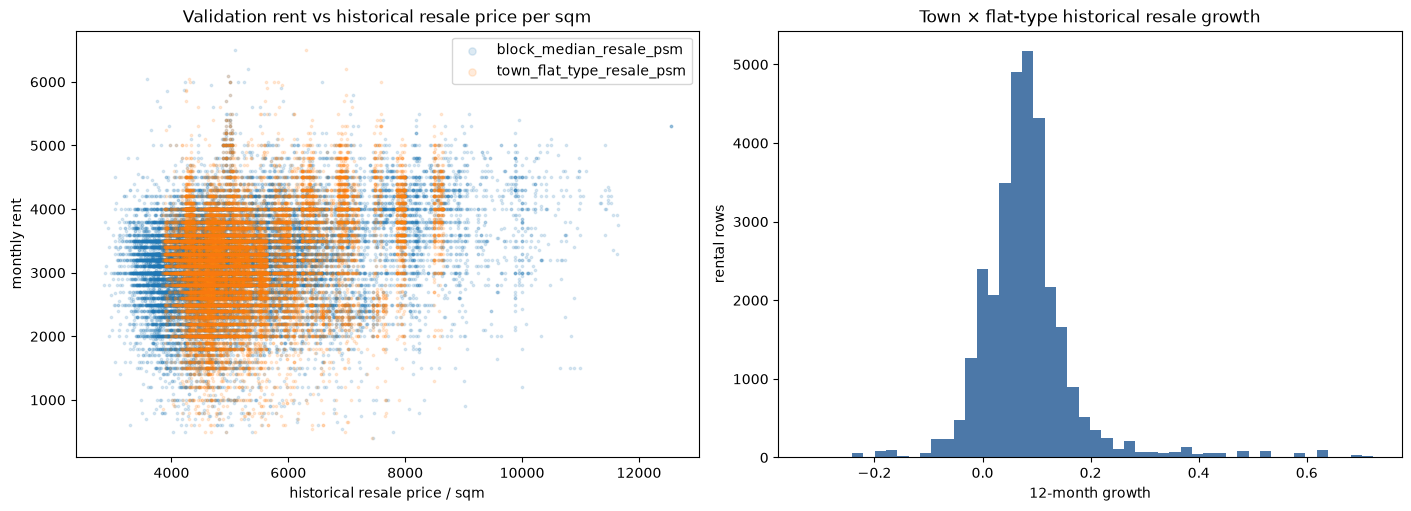

,validation_pearson_correlation
block_median_resale_psm,0.264580
street_median_resale_psm,0.257329
town_flat_type_resale_psm,0.248982
resale_price_growth_12m,0.050205


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for feature in ['block_median_resale_psm', 'town_flat_type_resale_psm']:
    axes[0].scatter(valid_x_best_resale[feature], valid_y, s=3, alpha=0.15, label=feature)
axes[0].set(title='Validation rent vs historical resale price per sqm', xlabel='historical resale price / sqm', ylabel='monthly rent')
axes[0].legend(markerscale=3)
axes[1].hist(valid_x_best_resale['resale_price_growth_12m'], bins=50, color='#4c78a8')
axes[1].set(title='Town × flat-type historical resale growth', xlabel='12-month growth', ylabel='rental rows')
plt.show()
display(valid_x_best_resale[resale_features].corrwith(valid_y).rename('validation_pearson_correlation').to_frame())


## AutoGluon comparison — Exp 9-compatible setup

This repeats the Exp 9 modelling setup: AutoGluon with LightGBM and CatBoost, `medium_quality` and `ignore_text` presets. The comparison of interest is the Exp 9 winner against the same winner plus historical resale features. The supplied validation period is used as `tuning_data`, matching Exp 9 exactly; therefore use this as an apples-to-apples experiment comparison rather than a completely untouched final estimate.

In [13]:
from autogluon.tabular import TabularPredictor

AUTOGLUON_TIME_LIMIT = int(os.environ.get('AUTOGLUON_TIME_LIMIT', '600'))
AUTOGLUON_RUN_ID = os.environ.get('AUTOGLUON_RUN_ID', pd.Timestamp.now().strftime('%Y%m%d_%H%M%S'))
AUTOGLUON_HYPERPARAMETERS = {'GBM': {}, 'CAT': {}}
ag_experiments = {
    'Exp 9 best feature set': (fit_x_best, valid_x_best),
    'Exp 9 best + historical resale': (fit_x_best_resale, valid_x_best_resale),
}

ag_models, ag_rows = {}, []
for name, (train_x, predict_x) in ag_experiments.items():
    safe_name = name.lower().replace(' ', '_').replace('+', 'plus')
    predictor = TabularPredictor(
        label=TARGET, problem_type='regression', eval_metric='root_mean_squared_error',
        path=str(project_root / 'exploration' / 'metul' / 'ag_exp_14_models' / AUTOGLUON_RUN_ID / safe_name),
    ).fit(
        train_data=train_x.assign(**{TARGET: fit_y}),
        tuning_data=predict_x.assign(**{TARGET: valid_y}),
        hyperparameters=AUTOGLUON_HYPERPARAMETERS,
        presets=['medium_quality', 'ignore_text'],
        time_limit=AUTOGLUON_TIME_LIMIT,
        verbosity=2,
    )
    prediction = predictor.predict(predict_x).astype(float).clip(lower=0)
    ag_models[name] = predictor
    ag_rows.append({
        'feature_set': name, 'features': train_x.shape[1],
        'RMSE': mean_squared_error(valid_y, prediction) ** 0.5,
        'MAE': mean_absolute_error(valid_y, prediction),
        'R2': r2_score(valid_y, prediction),
        'best_model': predictor.model_best,
    })

autogluon_comparison = pd.DataFrame(ag_rows).sort_values('RMSE').reset_index(drop=True)
display(autogluon_comparison)


Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.2
Python Version:     3.12.14
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.6.0: Fri Jul 31 19:16:20 PDT 2026; root:xnu-12377.161.14~5/RELEASE_ARM64_T8142
CPU Count:          10
Pytorch Version:    2.10.0
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       4.04 GB / 16.00 GB (25.2%)
Disk Space Avail:   170.30 GB / 460.38 GB (37.0%)
Presets specified: ['medium_quality', 'ignore_text']
Beginning AutoGluon training ... Time limit = 600s
AutoGluon will save models to "/Users/metul/Desktop/KDDM-project/exploration/metul/ag_exp_14_models/20261013_113740/exp_9_best_feature_set"
Train Data Rows:    117988
Train Data Columns: 18
Tuning Data Rows:    32012
Tuning Data Columns: 18
Label Column:       MONTHLY_RENT
Problem Type:       regr

,feature_set,features,RMSE,MAE,R2,best_model
0,Exp 9 best feature set,18,467.122316,340.293168,0.494477,WeightedEnsemble_L2
1,Exp 9 best + historical resale,22,467.563010,340.490894,0.493523,WeightedEnsemble_L2
